# RQ1A: Outputs

How do decision distributions, confidence and agreement differ across models on identical text? The saved analysis identifies every included model, dataset and feature revision.

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.utils.config import save_resolved_config
from src.utils.notebook_display import display_local, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.evaluation.decision_comparison import dataset_balanced
from src.evaluation.comparison_report import read_report, report_config
from src.evaluation.decision_diagnostics import case_browser, key_findings
from src.visualize import figures, style
from src.visualize import decision_diagnostics as plots
style.apply()
NOTEBOOK = "rq1/01_outputs"
begin_report()
save = figures.FigureSaver(NOTEBOOK)
cfg = report_config()
save_resolved_config(cfg, NOTEBOOK)
report_section("1. Compared models and denominators")
result, receipt = read_report(cfg, allow_previous_roster=True)
if receipt.get("unassessed_additions"):
    print("Additional models awaiting a new comparison snapshot:", ", ".join(receipt["unassessed_additions"]))
if receipt["status"] == "awaiting_cpu_report":
    print("Awaiting the RQ1A CPU summary. No measurements are available in this checkout.")
else:
    print(f"Verified summary from {receipt['origin']} · packaged {receipt['created_utc']}")
inventory = result.table("inventory")
coverage = (inventory.assign(available=inventory.status.eq("available"))
            .groupby("provider", sort=False)["available"].agg(["sum", "size"])
            .rename(columns={"sum": "Complete blocks", "size": "Expected blocks"}))
coverage.index = [style.DECISION_SHORT.get(p, p) for p in coverage.index]
display_local(coverage.rename_axis("Decision model").reset_index())
print("A block is one dataset and one representation (per-column or joint). Only models with all 36 blocks enter the comparison.")
row_summary = result.table("row_summary")
pairs = result.table("pairs")
if not row_summary.empty:
    denominators = row_summary[row_summary.representation.eq("joint") & row_summary.weighting.eq("unique_inputs")]
    missing = result.table("coverage").query("representation == 'joint'").groupby("dataset_id").missing_text_rows.first()
    denominators = denominators.assign(missing_joint_rows=denominators.dataset_id.map(missing))
    display_table("Rows, distinct joint inputs and rows without any text", denominators[["dataset", "models", "source_rows", "unique_inputs", "missing_joint_rows"]], preview_rows=18)
record(inventory, "Exact immutable feature artifact identities")

Additional models awaiting a new comparison snapshot: knowline, sieve
Verified summary from verified local export of 11 complete VSC models, 2026-11-18 · packaged 2026-11-18T13:24:39.664228+00:00


Decision model,Complete blocks,Expected blocks
Jev 1.14,0,36
Liquid d1-3B,36,36
Liquid d1-2B,36,36
Perplexity 27B,36,36
Clef-flash,36,36
Strands 2B,36,36
Intern 4B,36,36
H2O 4B,36,36
SII 27B,36,36
Kev 27B,36,36


A block is one dataset and one representation (per-column or joint). Only models with all 36 blocks enter the comparison.


dataset,models,source_rows,unique_inputs,missing_joint_rows
Fake Job Postings,11,12725,12674,0
Jigsaw Toxicity,11,99999,99661,1
Kickstarter,11,86502,86502,0
Data Scientist Salary,11,15841,12074,0
Michelin Guide,11,18843,18843,0
Product Sentiment,11,5091,5084,0
US Accidents,11,100001,96585,0
Wine Review,11,84123,78995,0
Women's Clothing,11,18122,18119,666
Baby Products,11,5085,5002,0


## Are the decision models interchangeable?

Each panel of the figure summarises one task. The lower triangle answers *do two models give the same answer?*; the upper triangle answers *do they order the rows in the same way?* The two can differ: models can agree on most answers while ranking rows differently near the decision boundary, or rank rows alike while one of them is shifted towards one class. Both ranking and probability magnitudes can matter to a tabular predictor. Their predictive value is tested in RQ2 rather than inferred from agreement or correlation alone.

Raw agreement also depends on how often each answer occurs. The table below adds the agreement expected from the two models' answer frequencies alone and Cohen's κ; both are descriptive, not significance tests.

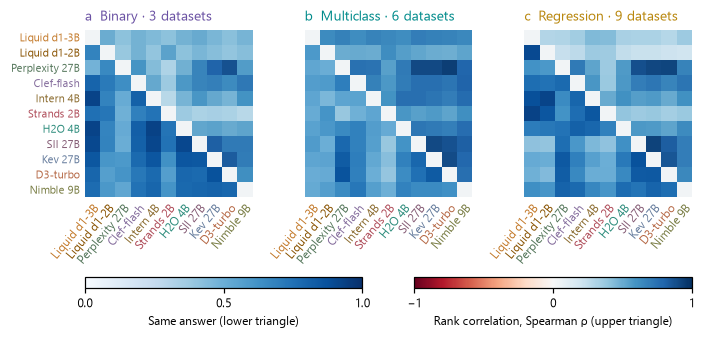

model_a,model_b,agreement,marginal_expected_agreement,cohen_kappa,representation_spearman,total_variation,datasets,task
Clef-flash,D3-turbo,0.720,0.626,0.294,0.631,0.220,3,binary_classification
Clef-flash,H2O 4B,0.818,0.722,0.313,0.576,0.170,3,binary_classification
Clef-flash,Intern 4B,0.812,0.722,0.275,0.514,0.192,3,binary_classification
Clef-flash,Kev 27B,0.777,0.696,0.291,0.682,0.185,3,binary_classification
Clef-flash,Nimble 9B,0.744,0.607,0.358,0.713,0.202,3,binary_classification
Clef-flash,SII 27B,0.811,0.704,0.320,0.660,0.179,3,binary_classification
Clef-flash,Strands 2B,0.690,0.615,0.154,0.360,0.255,3,binary_classification
D3-turbo,Nimble 9B,0.787,0.681,0.326,0.610,0.145,3,binary_classification
model_a,model_b,agreement,marginal_expected_agreement,cohen_kappa,representation_spearman,total_variation,datasets,task
Clef-flash,D3-turbo,0.720,0.626,0.294,0.631,0.220,3,binary_classification


In [2]:
report_section("2. Pairwise similarity")
for fig, name, caption in plots.similarity_figure(result):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)
if not pairs.empty:
    joint_pairs = pairs.query("representation == 'joint' and weighting == 'unique_inputs'")
    summary = pd.concat([dataset_balanced(frame, ["model_a", "model_b"], ["agreement", "marginal_expected_agreement", "cohen_kappa", "representation_spearman", "total_variation"]).assign(task=task)
                         for task, frame in joint_pairs.groupby("task", sort=False)])
    summary[["model_a", "model_b"]] = summary[["model_a", "model_b"]].apply(lambda c: c.map(style.DECISION_SHORT))
    display_table("Pairwise similarity per task (equal dataset weight)", summary.round(3), preview_rows=8)
    record(summary, "Pairwise similarity per task, equal dataset weight")
record(pairs, "All pairwise metrics by dataset, field and weighting")

## Which models deviate from the others, and where?

The figure places every model against the average of the *other* models (a) and shows how concentrated its own probabilities are (b). Dots are datasets, so a model that is distant on every dataset is distinguishable from one that differs on a few. A model can be distant because it is more confident than the others, because it is less confident, or because it prefers other answers; panel (b) separates the first two.

The figure then asks, for every dataset, how often each model gives the answer that most other models give. It locates systematic deviation in specific datasets and tasks. Inputs where the other models are tied are excluded and counted in the table.

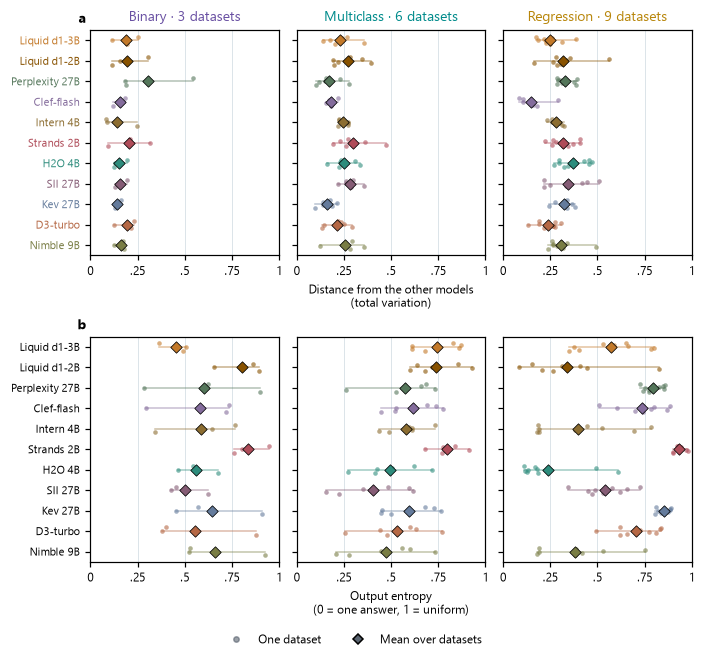

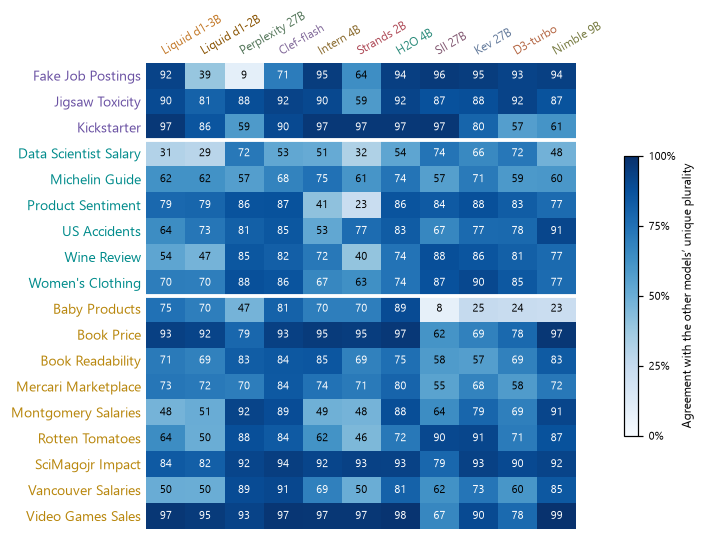

task,provider,agreement,datasets,lowest,inputs,tied_peer_inputs
binary_classification,Liquid d1-3B,0.929,3,0.897,188709,10128
binary_classification,Liquid d1-2B,0.687,3,0.394,189981,8856
binary_classification,Perplexity 27B,0.521,3,0.093,192244,6593
binary_classification,Clef-flash,0.843,3,0.706,190651,8186
binary_classification,Strands 2B,0.730,3,0.587,189620,9217
binary_classification,Intern 4B,0.939,3,0.903,188786,10051
binary_classification,H2O 4B,0.942,3,0.920,188614,10223
binary_classification,SII 27B,0.935,3,0.873,188601,10236
task,provider,agreement,datasets,lowest,inputs,tied_peer_inputs
binary_classification,Liquid d1-3B,0.929,3,0.897,188709,10128


SII 27B agrees with the other models' unique plurality on 8% of 4,397 Baby Products inputs.
Perplexity 27B agrees with the other models' unique plurality on 9% of 12,329 Fake Job Postings inputs.
Nimble 9B agrees with the other models' unique plurality on 23% of 4,384 Baby Products inputs.
Strands 2B agrees with the other models' unique plurality on 23% of 4,904 Product Sentiment inputs.
D3-turbo agrees with the other models' unique plurality on 24% of 4,395 Baby Products inputs.


In [3]:
report_section("3. Model profiles and agreement with the peer plurality")
for fig, name, caption in plots.model_profile_figure(result):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)
majority = result.table("peer_majority")
for fig, name, caption in plots.peer_majority_figure(majority):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)
if not majority.empty:
    per_task = (majority.groupby(["task", "provider"], sort=False)
                .agg(agreement=("agreement", "mean"), datasets=("dataset", "size"), lowest=("agreement", "min"),
                     inputs=("n", "sum"), tied_peer_inputs=("tied_peers", "sum")).reset_index())
    per_task["provider"] = per_task.provider.map(style.DECISION_SHORT)
    display_table("Agreement with the peer plurality per task (equal dataset weight)", per_task.round(3), preview_rows=8)
    record(per_task, "Agreement with the peer plurality per task")
    lowest = majority.nsmallest(5, "agreement")
    for row in lowest.itertuples():
        print(f"{style.DECISION_SHORT.get(row.provider, row.provider)} agrees with the other models' unique plurality on {row.agreement:.0%} of {row.n:,} {row.dataset} inputs.")
if "agreement_tied_models_abstain" in majority and majority["agreement_tied_models_abstain"].notna().any():
    display_table("Sensitivity when tied models abstain", majority[["dataset", "provider", "agreement", "agreement_tied_models_abstain", "n_tied_models_abstain"]])
else:
    record("The verified snapshot predates per-model tie flags. The abstention comparison requires a fresh RQ1A export.")
record(majority, "Agreement with the peer plurality per dataset")
record(result.table("consensus"), "Distance from the other models and tie counts")
record(result.table("distributions"), "Full distribution summaries of the features, entropy and maximum probability")

## What does disagreement look like?

The figure shows, for each task, the distinct input on which the models' probability vectors differ most, chosen without target values. These are deliberate extremes, not typical inputs. The browser below gives three label-free cases for every dataset where available: the most disputed input, the unanimous input with the most similar probabilities, and the unanimous input with the most different probabilities. Each entry shows the **exact verified request** (question, definitions, options and source text), the source row, how often the text occurs and all probabilities. Text quoted in a paper still needs editorial review.

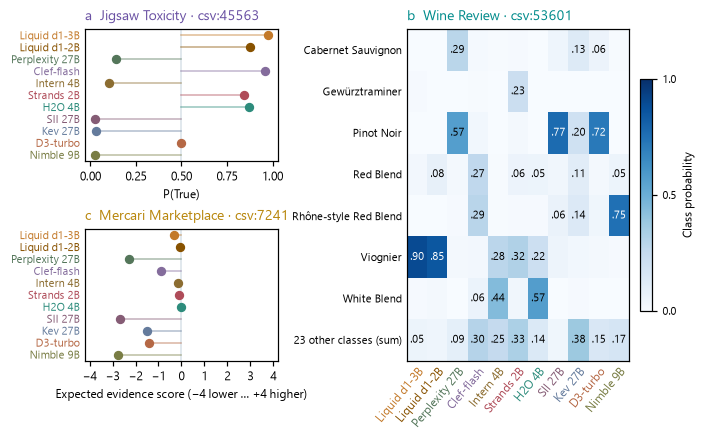

dataset,row_id,vote_pattern,mean_pair_tv,score_range,input_multiplicity,payload_status
Fake Job Postings,csv:2768,7:4,0.436309,NaN,1,Exact payload hash verified
Jigsaw Toxicity,csv:45563,6:5,0.483225,NaN,1,Exact payload hash verified
Kickstarter,csv:40813,6:5,0.453312,NaN,1,Exact payload hash verified
Data Scientist Salary,csv:14373,4:4:2:1,0.560595,NaN,1,Exact payload hash verified
Michelin Guide,csv:13281,6:5,0.566014,NaN,1,Exact payload hash verified
Product Sentiment,csv:4454,5:2:2:2,0.548804,NaN,1,Exact payload hash verified
US Accidents,csv:3992,5:3:2:1,0.494992,NaN,1,Exact payload hash verified
Wine Review,csv:53601,4:3:2:2,0.726577,NaN,1,Exact payload hash verified
Women's Clothing,csv:12368,5:4:2,0.635280,NaN,1,Exact payload hash verified
Baby Products,csv:1369,7:4,0.491313,2.580659,1,Exact payload hash verified


,cloudflare,decision3,h2o,intern,kev,liquid,liquid_lfm3,nimble,perplexity,sii,strands
0,0.7677,0.962,0.0748,0.1251,0.9464,0.3775,0.0546,0.0953,0.3499,0.9399,0.2209
1,0.2323,0.038,0.9252,0.8749,0.0536,0.6225,0.9454,0.9047,0.6501,0.0601,0.7791
,cloudflare,decision3,h2o,intern,kev,liquid,liquid_lfm3,nimble,perplexity,sii,strands
0,0.0421,0.0407,0.0643,0.0469,0.0372,0.0421,0.0327,0.0036,0.0013,0.0159,0.1279
1,0.9579,0.9593,0.9357,0.9531,0.9628,0.9579,0.9673,0.9964,0.9987,0.9841,0.8721
,cloudflare,decision3,h2o,intern,kev,liquid,liquid_lfm3,nimble,perplexity,sii,strands
0,0.8926,0.9853,0.9021,0.7888,0.947,0.9627,0.5117,0.9859,0.5155,0.9707,0.6475
1,0.1074,0.0147,0.0979,0.2112,0.053,0.0373,0.4883,0.0141,0.4845,0.0293,0.3525
,cloudflare,decision3,h2o,intern,kev,liquid,liquid_lfm3,nimble,perplexity,sii,strands
False,0.0405,0.5013,0.1298,0.8999,0.9719,0.026,0.1232,0.977,0.8578,0.977,0.1567


In [4]:
report_section("4. Exact cases")
cases = result.table("cases")
for fig, name, caption in plots.disputed_cases_figure(cases):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)
if not cases.empty:
    display_table("Most disputed input in every dataset", cases[cases.category.eq("disputed")][["dataset", "row_id", "vote_pattern", "mean_pair_tv", "score_range", "input_multiplicity", "payload_status"]], preview_rows=18)
    display(case_browser(cases))
    record(cases, "Complete exact case payloads and all model probabilities")

## Findings and a searchable record of every row

The findings below are computed from the saved features; **no predictive benefit or correctness is inferred**. The compressed `joint_rows.parquet` keeps every source row: dataset and row ID, input hash, missing-text status, every model's answer, the vote pattern, ties, unanimity, mean and maximum pairwise distance, confidence, text multiplicity and regression scores. Filter by `dataset_id`, sort `mean_pair_tv` descending for disagreement, or select `unanimous == True` for consensus. Classification answers are indices into the canonical class labels kept in the cases and feature manifests.

In [5]:
report_section("5. Measured findings and saved analysis")
findings = key_findings(result)
for finding in findings:
    print(finding)
record(findings, "Measured descriptive findings")
record({"status": receipt["status"], "joint_rows": receipt.get("joint_rows"),
        "source": receipt.get("origin"), "snapshot_sha256": receipt.get("receipt_sha256"),
        "target_labels_used": False, "provider_calls": 0}, "Execution scope")

binary classification: across 3 datasets, 11-model unambiguous consensus averages 24.1% (equal dataset weight); Fake Job Postings 1.0% to Jigsaw Toxicity 39.4%.
multiclass classification: across 6 datasets, 11-model unambiguous consensus averages 14.9% (equal dataset weight); Data Scientist Salary 0.5% to Women's Clothing 26.0%.
regression: across 9 datasets, 11-model unambiguous consensus averages 27.8% (equal dataset weight); Baby Products 1.3% to Video Games Sales 60.7%.
binary classification: intern and h2o have the largest mean same-answer fraction (92.6%), but their rank correlation is 0.46 and probability distance is 0.14. This identifies similar decisions, not the best predictor.
multiclass classification: perplexity and decision3 have the largest mean same-answer fraction (86.6%), but their rank correlation is 0.94 and probability distance is 0.11. This identifies similar decisions, not the best predictor.
regression: liquid and strands have the largest mean same-answer fracti

## When do all models agree, and does the text they see matter?

The figure shows, for every dataset, how many models side with the most common answer. The participating model count is reported with each result. Tied votes are kept separate from a unique majority; multiclass and regression votes can split across more than two answers. The figure compares the unanimous share when a request contains one text field (per-column) with the share when it contains all fields (joint). The two modes contain different information, so the comparison is descriptive, not a controlled effect of combining fields.

Exact repeated texts can dominate a row-weighted average. The figures count each distinct input once; the table reports how much the unanimous share changes when every source row counts instead.

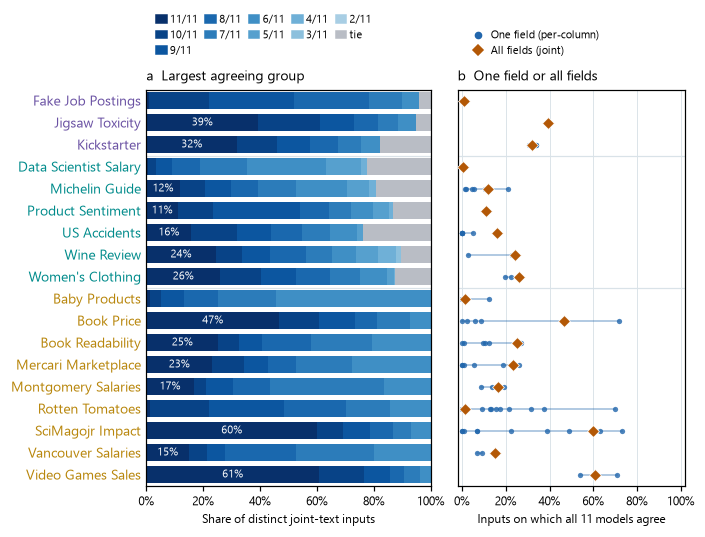

dataset,position,text_column,unanimous,n
Baby Products,Least consensus,company_struct,0.000000,193
Baby Products,Most consensus,colors,0.123288,146
Book Price,Least consensus,Author,0.002257,3102
Book Price,Most consensus,Edition,0.715746,2934
Book Readability,Least consensus,British Words,0.000000,250
Book Readability,Most consensus,Anthology,0.268966,290
dataset,position,text_column,unanimous,n
Baby Products,Least consensus,company_struct,0.000000,193
Baby Products,Most consensus,colors,0.123288,146
Book Price,Least consensus,Author,0.002257,3102


weighting,dataset,rows,unique_inputs,change_pp
,Video Games Sales,0.534,0.607,-7.347
,Vancouver Salaries,0.108,0.150,-4.138
,Book Price,0.463,0.467,-0.384
,US Accidents,0.155,0.158,-0.324
,Wine Review,0.243,0.244,-0.139
,Data Scientist Salary,0.005,0.005,-0.038
weighting,dataset,rows,unique_inputs,change_pp
,Video Games Sales,0.534,0.607,-7.347
,Vancouver Salaries,0.108,0.150,-4.138
,Book Price,0.463,0.467,-0.384


In [6]:
report_section("6. All-model consensus and the presented text")
for fig, name, caption in plots.consensus_figure(result):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)
if not row_summary.empty:
    fields = row_summary.query("representation == 'per_column' and weighting == 'unique_inputs'")
    extremes = pd.concat([fields.loc[fields.groupby("dataset").unanimous.idxmin()].assign(position="Least consensus"), fields.loc[fields.groupby("dataset").unanimous.idxmax()].assign(position="Most consensus")]).sort_values(["dataset", "position"])
    display_table("Text fields with the least and most consensus", extremes[["dataset", "position", "text_column", "unanimous", "n"]], preview_rows=6)
    reuse = row_summary[row_summary.representation.eq("joint")].pivot(index="dataset", columns="weighting", values="unanimous")
    reuse = reuse.assign(change_pp=100 * (reuse.rows - reuse.unique_inputs)).sort_values("change_pp")
    display_table("Unanimous share: source rows minus distinct inputs (percentage points)", reuse.round(3), preview_rows=6)
    record(reuse, "Duplicate-weighting sensitivity of joint-text consensus")
record(result.table("vote_patterns"), "Complete vote patterns, including ties, under both weightings")
record(row_summary, "All-model consensus and probability-distance summaries")

## Complete report

In [7]:
finish_report(NOTEBOOK, save.summary() + "\nOnly saved evidence was analysed; no inference, model training or live VSC changes were performed.")

rq1/01_outputs

1. Compared models and denominators

Decision model  Complete blocks  Expected blocks
      Jev 1.14                0               36
  Liquid d1-3B               36               36
  Liquid d1-2B               36               36
Perplexity 27B               36               36
    Clef-flash               36               36
    Strands 2B               36               36
     Intern 4B               36               36
        H2O 4B               36               36
       SII 27B               36               36
       Kev 27B               36               36
      D3-turbo               36               36
     Nimble 9B               36               36
     GLiDE 27B                0               36
   Mammoth 27B                0               36
  Drex Max 27B                0               36


Rows, distinct joint inputs and rows without any text
              dataset  models  source_rows  unique_inputs  missing_joint_rows
    Fake Job Postings      11